In [7]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from neurogym.wrappers import ScheduleEnvs, Monitor
from neurogym.utils import plot_env, RandomSchedule, SequentialSchedule
from neurogym.envs import get_collection
from torch.nn import functional as F
from IPython.display import clear_output
warnings.filterwarnings("ignore")
clear_output()

In [ ]:
pos = np.random.choice(10, )

In [8]:
dt = 100
dim_ring = 2
kwargs = {'dt': dt, 'dim_ring': dim_ring}
seq_len = 100

# Make supervised dataset
task = "go"
task = f"yang19.{task}-v0"
env = ngym.make(task, **kwargs)

In [9]:
print('timing:', env.timing)
print('dt:', env.dt)
print('tmax:', env.tmax)

trial = env.new_trial()
# data["trial"].append(trial)
ob, gt = env.ob, env.gt
# data["gt"].append(gt[-1])
trial_length = ob.shape[0]
print('trial length:', trial_length)

timing: {'fixation': 500, 'stimulus': 500, 'delay': 0, 'decision': 500}
dt: 100
tmax: 10000
trial length: 15


In [10]:
# Environment parameters
# This setting is low to speed up testing, we recommend setting it to at least 1000
EVAL_TRIALS = 100
dt = 100
dim_ring = 2  # Number of choices in the ring representation

rewards = {
    "abort": -0.1,
    "correct": +1.0,
    "fail": 0.0
}
sigma = 1.0 # Standard deviation of the Gaussian noise in the ring representation

In [11]:
kwargs = {'dt': dt, 'dim_ring': dim_ring}
seq_len = 100

# Make supervised dataset
tasks = get_collection('yang19')
envs = [ngym.make(task, **kwargs) for task in tasks]
schedule = RandomSchedule(len(envs))
# schedule = SequentialSchedule(len(envs))
env = ScheduleEnvs(envs, schedule=schedule, env_input=True)

# Print environment specifications
print("Trial timing (in milliseconds):")
print(env.timing)

print("\nObservation space structure:")
print(env.observation_space)

print("\nAction space structure:")
print(env.action_space)
print("Action mapping:")
print(env.action_space.name)

Trial timing (in milliseconds):
{'fixation': 500, 'stimulus': 500, 'delay': 0, 'decision': 500}

Observation space structure:
Box(-inf, inf, (25,), float32)

Action space structure:
Discrete(3)
Action mapping:
{'fixation': 0, 'choice': range(1, 3)}


In [45]:
# net.eval()
# Initialize storage for each environment
EVAL_TRIALS = 5
env_timing = {}
print('len:', len(env.envs))
dt = env.envs[0].dt
hidden_size = 25
hidden_dict = {}
for e_i in env.envs:
    hidden_dict[e_i.spec.id] = dict()
for env_idx, e_i in enumerate(env.envs):
    total_correct = 0
    timing = e_i.timing
    timing_index = dict()
    env_timing[e_i.spec.id] = timing_index
    print(f"\nEvaluating environment {env_idx + 1}/{len(env.envs)}: {e_i.spec.id}")
    print('start_index:', e_i.start_ind)
    print('end_index:', e_i.end_ind)
    period_keys = list(e_i.start_ind.keys())
    trial_length = max(list(e_i.end_ind.values()))
    hidden_ar = np.zeros((2, EVAL_TRIALS, len(period_keys), hidden_size))
    for trial_idx in range(EVAL_TRIALS):
        trial = e_i.new_trial()
        print(f"Trial {trial_idx + 1}/{EVAL_TRIALS}")
        print('start_index:', e_i.start_ind)
        print('end_index:', e_i.end_ind)
        ob, gt = e_i.ob, e_i.gt
        trial_length = ob.shape[0]

        # Add one-hot encoding for the environment
        env_one_hot = np.zeros((trial_length, len(env.envs)))
        env_one_hot[:, env_idx] = 1.0  # Set the current environment index to 1

        # Concatenate original observation with one-hot encoding
        ob_with_env = np.concatenate([ob, env_one_hot], axis=1)

        ob_with_env = ob_with_env[:, np.newaxis, :]  # Add batch dimension
        inputs = torch.from_numpy(ob_with_env).float()
        # hidden = sl_model.init_hidden(1, device)
        hidden = inputs[:,0,:]
        for i, k in enumerate(period_keys):
            start_ind = e_i.start_ind[k]
            end_ind = e_i.end_ind[k]
            hidden_slice = hidden[start_ind:end_ind, :]
            hidden_ar[0, trial_idx, i, :] = hidden_slice.mean(dim=0).detach().numpy()
            hidden_ar[1, trial_idx, i, :] = hidden_slice.var(dim=0).detach().numpy()

    for i, k in enumerate(period_keys):
        period_mean = hidden_ar[0, :, i, :].mean(axis=0)
        period_var = hidden_ar[1, :, i, :].mean(axis=0) + hidden_ar[0, :, i, :].var(axis=0)
        hidden_dict[e_i.spec.id][k] = np.stack([period_mean, period_var],0)


titles = []
data = []
for k, v in hidden_dict.items():
    print(f"\nEnvironment: {k}")
    env_name = k.split('.')[1].split('-')[0]
    for k2, v2 in v.items():
        print(f"Period:{k2}, {v2.shape}")
        titles.append(f"{env_name} {k2}")
        data.append(v2[1])
print(titles)
data = np.array(data)
data_normalized = (data - data.min())/(data.max() - data.min())


len: 20

Evaluating environment 1/20: yang19.go-v0
start_index: {'fixation': 0, 'stimulus': 5, 'delay': 10, 'decision': 10}
end_index: {'fixation': 5, 'stimulus': 10, 'delay': 10, 'decision': 15}
Trial 1/5
start_index: {'fixation': 0, 'stimulus': 5, 'delay': 10, 'decision': 10}
end_index: {'fixation': 5, 'stimulus': 10, 'delay': 10, 'decision': 15}
Trial 2/5
start_index: {'fixation': 0, 'stimulus': 5, 'delay': 10, 'decision': 10}
end_index: {'fixation': 5, 'stimulus': 10, 'delay': 10, 'decision': 15}
Trial 3/5
start_index: {'fixation': 0, 'stimulus': 5, 'delay': 10, 'decision': 10}
end_index: {'fixation': 5, 'stimulus': 10, 'delay': 10, 'decision': 15}
Trial 4/5
start_index: {'fixation': 0, 'stimulus': 5, 'delay': 10, 'decision': 10}
end_index: {'fixation': 5, 'stimulus': 10, 'delay': 10, 'decision': 15}
Trial 5/5
start_index: {'fixation': 0, 'stimulus': 5, 'delay': 10, 'decision': 10}
end_index: {'fixation': 5, 'stimulus': 10, 'delay': 10, 'decision': 15}

Evaluating environment 2/20:

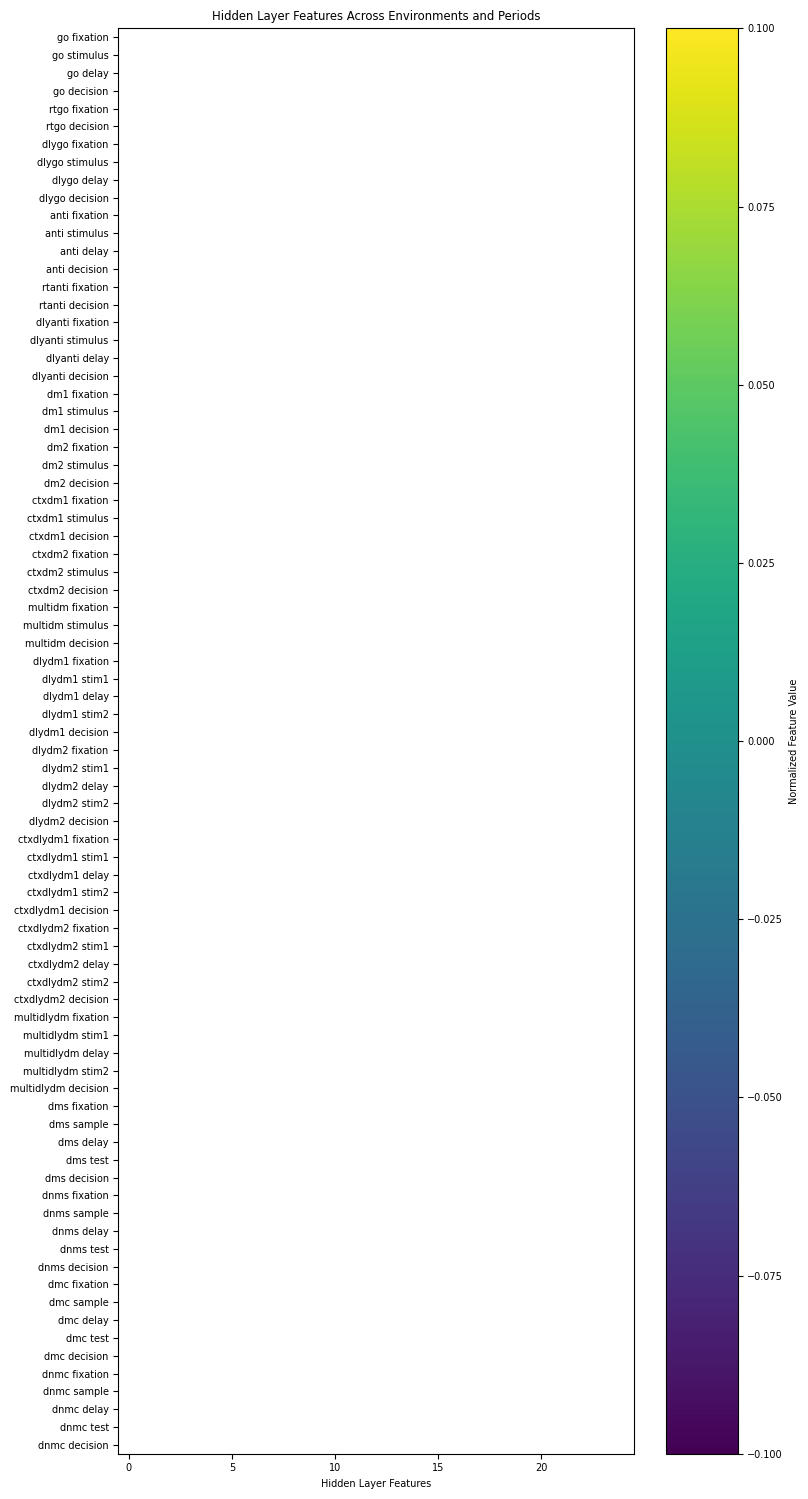

In [47]:
fig, ax = plt.subplots(figsize=(8, 15))
im = ax.imshow(data_normalized, aspect='auto', cmap='viridis', interpolation='nearest')
ax.set_yticks(np.arange(len(titles)))
ax.set_yticklabels(titles)
ax.set_xlabel('Hidden Layer Features')
ax.set_title('Hidden Layer Features Across Environments and Periods')
plt.colorbar(im, ax=ax, label='Normalized Feature Value')
plt.tight_layout()
plt.show()

In [49]:
print(data)

[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.1024     0.1536     ... 0.         0.         0.        ]
 [       nan        nan        nan ...        nan        nan        nan]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.11307002 0.15142119 ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]


In [38]:
max(list(e_i.end_ind.values()))

15

In [ ]:
seq_len = 100
print(f"Using sequence length: {seq_len}")

# Make supervised dataset
batch_size = 32
print(f"Creating dataset with batch_size={batch_size}")
dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

env = dataset.env

# Extract dimensions
ob_size = env.observation_space.shape[0]
act_size = env.action_space.n
# 20 observations for one-hot encoding of the 20 environments, 1 for fixation,
# 2 for each modality (2 modalities, 4 observations total), for a total of 25 observations
print(f"Observation size: {ob_size}")
print(f"Action size: {act_size}")

# Get a batch of data
# inputs, target = dataset()
# print(f"Input batch shape: {inputs.shape}")
# print(f"Target batch shape: {target.shape}")
# print(inputs[90])

# Set device
device = 'cuda'
print(f"Using device: {device}")

In [15]:
seq_len = 100
print(f"Using sequence length: {seq_len}")

# Make supervised dataset
batch_size = 32
print(f"Creating dataset with batch_size={batch_size}")
dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

env = dataset.env
trial = env.new_trial()
ob, gt = env.ob, env.gt
trial_length = ob.shape[0]
dt = env.dt
print(env.in_period("fixation"))
print('trial length:', trial_length)
print('timing:', env.timing)
print('dt:', env.dt)
print('tmax:', env.tmax)
gt_phase = []
for k, v in env.timing.items():
    length = v//dt
    gt_phase.append(length)
gt_phase = np.array(gt_phase)
print('gt_phase:', gt_phase)

Using sequence length: 100
Creating dataset with batch_size=32
Copying environment for dataset.
timing: {'fixation': <function _DMFamily.__init__.<locals>.<lambda> at 0x7faa2cc1d1c0>, 'stim1': 500, 'delay': 1000, 'stim2': 500, 'decision': 200}
dt: 100
tmax: 2600
True
trial length: 15
timing: {'fixation': 500, 'stimulus': 500, 'delay': 0, 'decision': 500}
dt: 100
tmax: 1500
gt_phase: [5 5 0 5]
